# Ray Serve: an OpenAI-compatible LLM endpoint

An LLM node builds an OpenAI-compatible app with ray.serve.llm: model id, model files on Hugging Face, accelerator type and autoscaling bounds.

**When to use it.** Hosting an open-weights chat model behind the OpenAI API shape. Shown as code only: it needs a GPU and vLLM.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Code only.** Running this notebook needs a GPU (the node asks for an A10G) and vLLM. It was not run for this gallery, so it has no outputs.
>
> Importing ray.serve.llm needs Ray's LLM extras (vLLM or SGLang). The API names used here were checked against the Ray 2.55.1 sources.

[Back to the gallery](../README.md) · Written for Ray 2.55.1

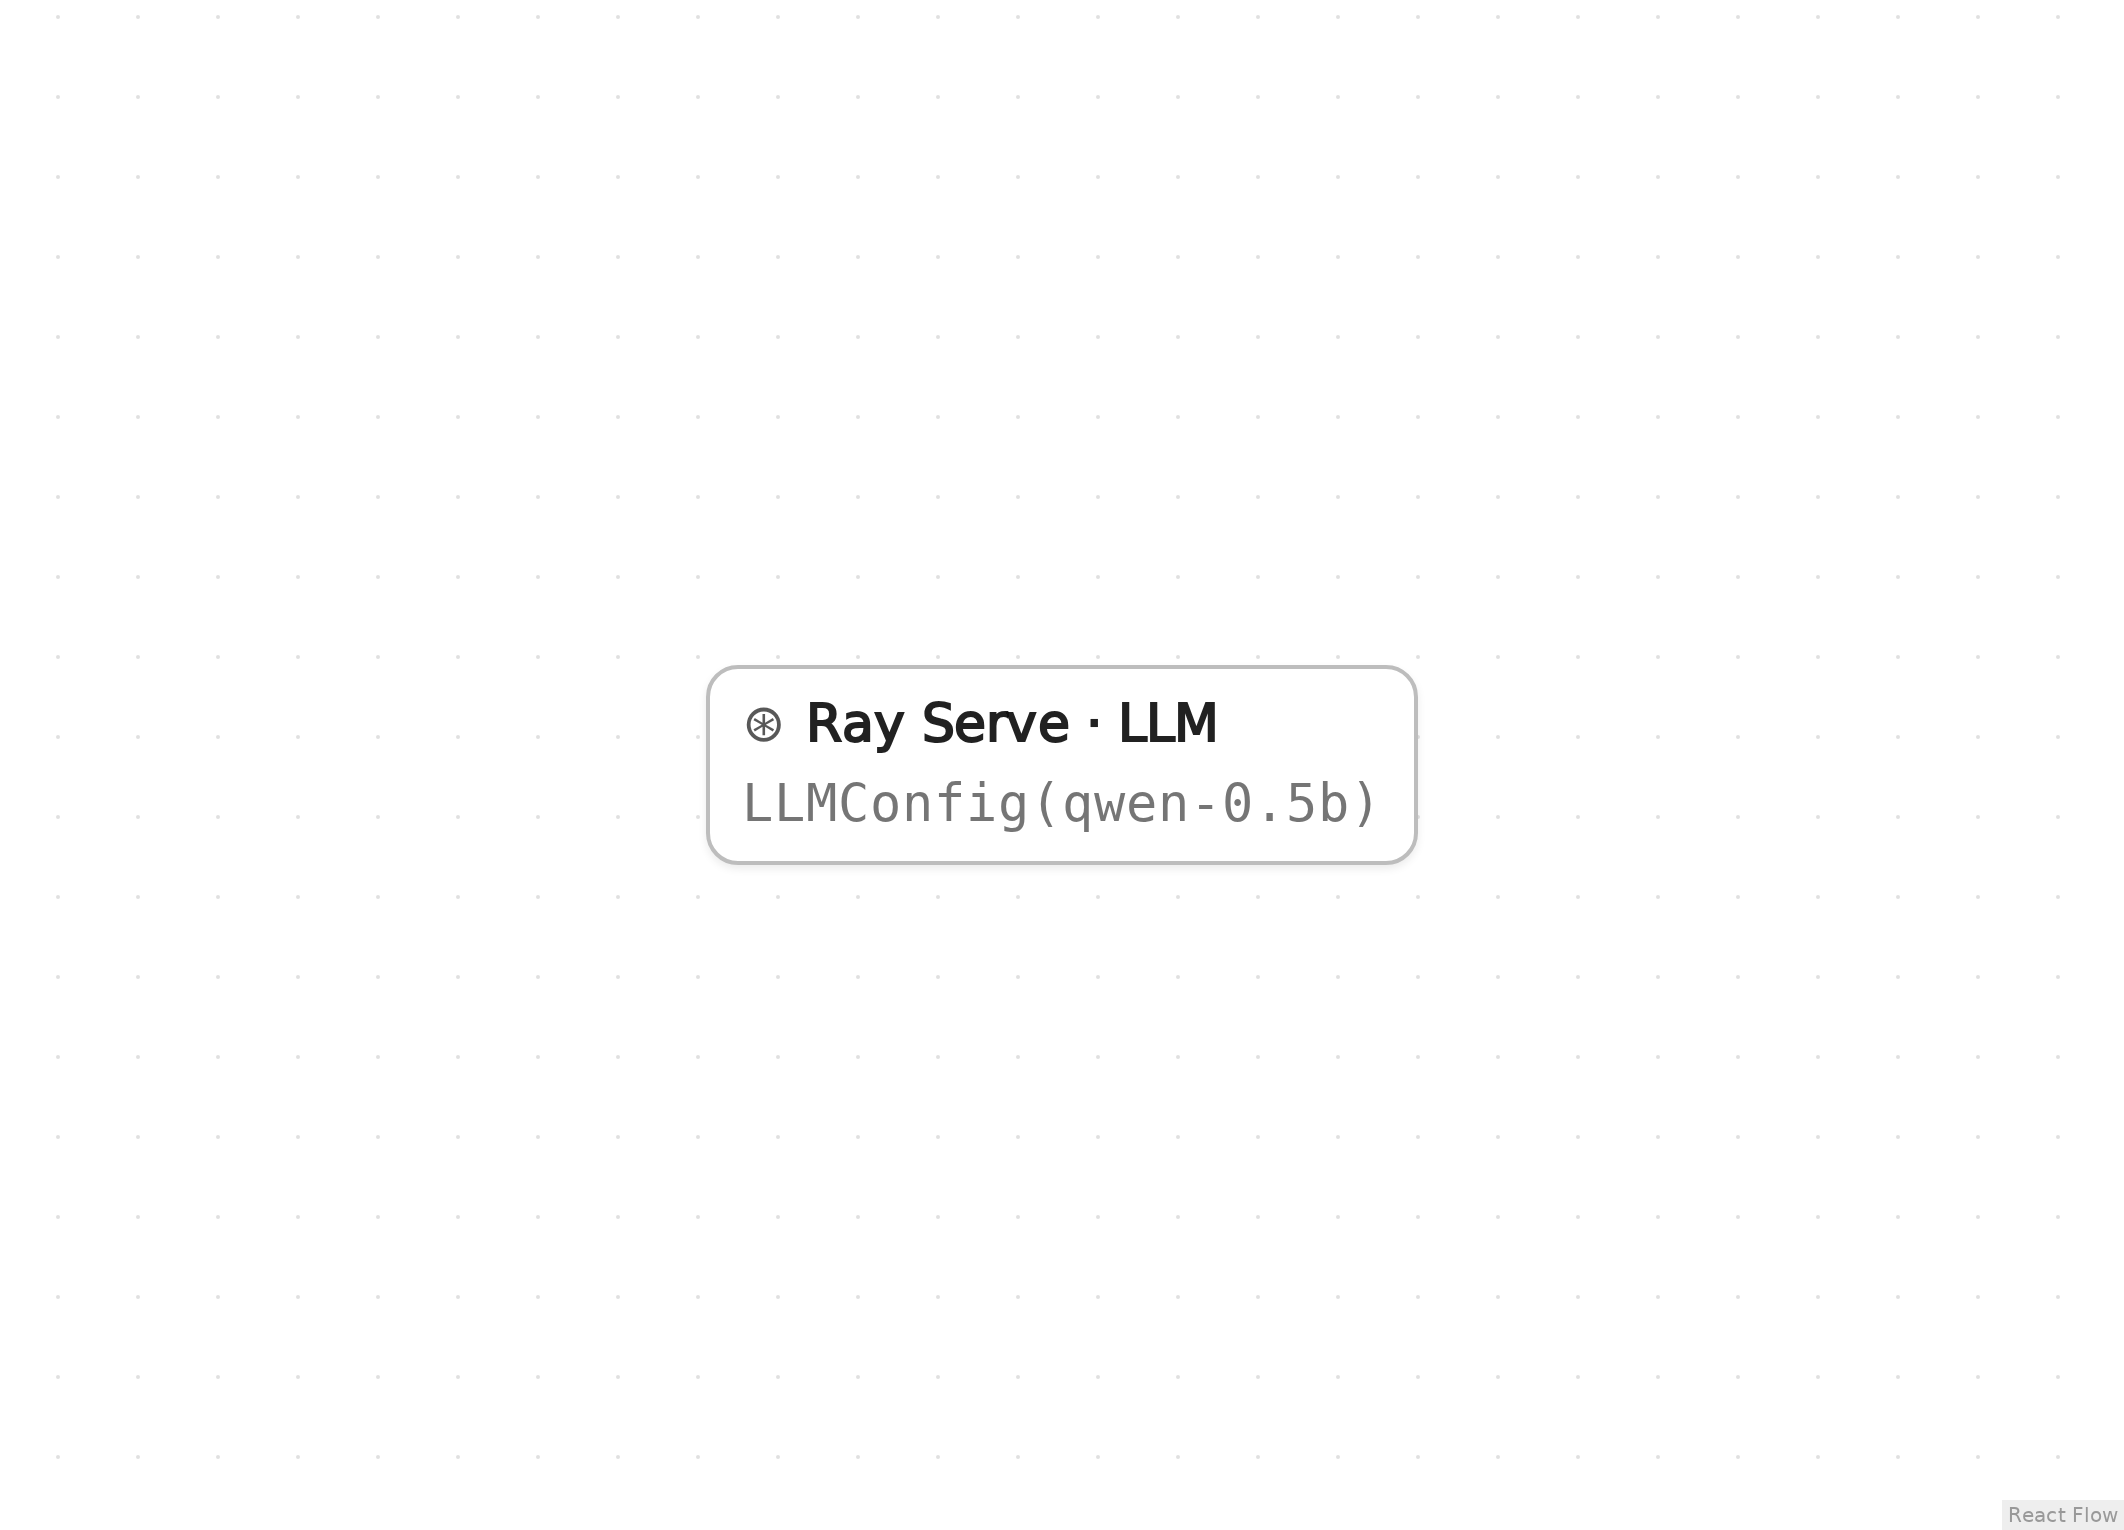

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is not capped at a CPU count here, so it can see the machine's GPUs. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [ ]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR")

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [ ]:
# This pattern needs no user functions.
from ray import serve

## Generated code

This is the cell the visual builder generated from the graph above.

In [ ]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray
from ray.serve.llm import LLMConfig, build_openai_app

if not ray.is_initialized():
    ray.init()

_llm_cfg_n1 = LLMConfig(model_loading_config=dict(model_id="qwen-0.5b", model_source="Qwen/Qwen2.5-0.5B-Instruct"), deployment_config=dict(autoscaling_config=dict(min_replicas=1, max_replicas=2)), accelerator_type="A10G")
_llm_app = build_openai_app({"llm_configs": [_llm_cfg_n1]})
serve.run(_llm_app)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [ ]:
from openai import OpenAI

client = OpenAI(base_url="http://127.0.0.1:8000/v1", api_key="not-needed")
reply = client.chat.completions.create(model="qwen-0.5b", messages=[{"role": "user", "content": "Say hello."}])
print(reply.choices[0].message.content)

## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–5 and 7–8)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
from ray.serve.llm import LLMConfig, build_openai_app
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**LLM** (node `n1`, lines 10–12)

```python
_llm_cfg_n1 = LLMConfig(model_loading_config=dict(model_id="qwen-0.5b", model_source="Qwen/Qwen2.5-0.5B-Instruct"), deployment_config=dict(autoscaling_config=dict(min_replicas=1, max_replicas=2)), accelerator_type="A10G")
_llm_app = build_openai_app({"llm_configs": [_llm_cfg_n1]})
serve.run(_llm_app)
```

LLMConfig names the model (model_id), where to load it from (model_source), the accelerator and the replica range; build_openai_app wraps it in /v1/chat/completions-style routes.

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [ ]:
from ray import serve

serve.shutdown()
ray.shutdown()